In [44]:
import pandas as pd
import numpy as np
from itertools import permutations
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [20]:
filepath = "/Users/benjaminsumacbookm4/Desktop/Pairs Trading/data/market_data/IntradayMarketDataGOOG_GOOGL_V2"
data = pd.read_parquet(filepath)

In [21]:
data.head()

,symbol,timestamp,close
0,GOOGL,2020-11-23 12:30:00+00:00,4.465908
1,GOOGL,2020-11-23 12:47:00+00:00,4.465908
2,GOOGL,2020-11-23 12:55:00+00:00,4.465908
3,GOOGL,2020-11-23 13:00:00+00:00,4.464758
4,GOOGL,2020-11-23 13:05:00+00:00,4.466023


In [22]:
data.tail()

,symbol,timestamp,close
1051372,GOOG,2024-11-20 22:37:00+00:00,5.178971
1051373,GOOG,2024-11-20 22:41:00+00:00,5.179534
1051374,GOOG,2024-11-20 22:47:00+00:00,5.179478
1051375,GOOG,2024-11-20 22:56:00+00:00,5.178463
1051376,GOOG,2024-11-21 00:00:00+00:00,5.180378


In [23]:
# Show timestamps in New York time so the session is 09:30–16:00 year-round (handles DST)
data["timestamp"] = data["timestamp"].dt.tz_convert("America/New_York")

prices = (
    data.pivot(index="timestamp", columns="symbol", values="close")
        .between_time("09:30", "15:59") # Normalizes time to regular business hours
        .dropna()
)
prices.head()
prices["GOOG"].shape

(372890,)

- score = more negative means more likely to be not cointegrated
- pvalue = Smaller value rejects null hypothesis of lack of cointegration
- crit_value = depends if 0, 1, or 2. Rejects cointegration at 99% probability if score < crit_value[0], 95% if score < crit_value[1], 90% if score < crit_value[2]

In [24]:
score, pvalue, crit_value = coint( 
    prices["GOOG"], 
    prices["GOOGL"],
    trend="c",
    autolag="AIC"
)

print(f"Score: {score}")
print(f"P-value: {pvalue}")
print(f"Critical Value {crit_value}")

Score: -4.784216821408521
P-value: 0.00040233064286273815
Critical Value [-3.89646937 -3.33614639 -3.04446137]


In [25]:
if score < crit_value[0]:
    print("There is a 99% chance of cointegration!")
elif score < crit_value[1]:
    print("There is a 95% chance of cointegration!")
elif score < crit_value[2]:
    print("There is a 90% chance of cointegration!")
else:
    print("There is no statistically significant cointegration in the dataset. ")

There is a 99% chance of cointegration!


Linear Regression Test to Establish Optimal Hedge Ratio

In [26]:
x = prices["GOOG"].to_numpy()
y = prices["GOOGL"].to_numpy()

In [27]:
slope, intercept = np.polyfit(x, y, deg=1)

In [28]:
y_prediction = slope * x + intercept

In [29]:
ss_res = np.sum((y-y_prediction) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - ss_res/ss_tot

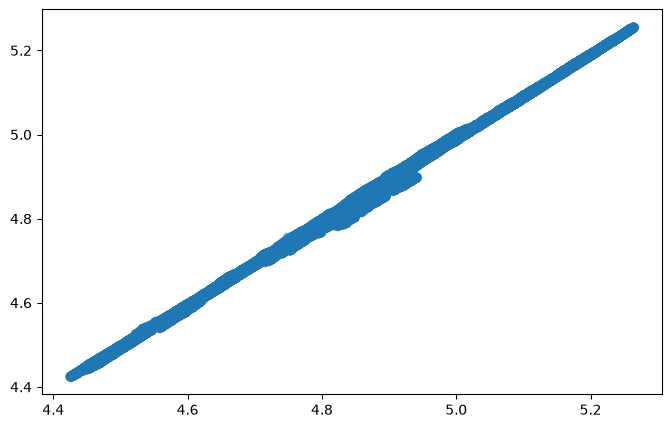

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.5, label="Prices of GOOG vs GOOGL")



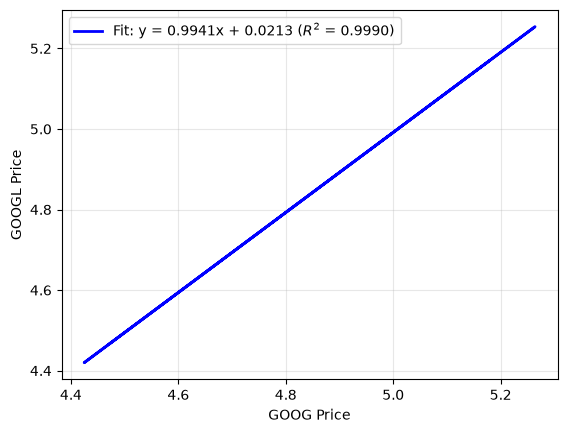

In [ ]:
sort_idx = np.argsort(x)
plt.plot(
    x[sort_idx],
    y_prediction[sort_idx],
    color = "blue",
    linewidth=2,
    label = f"Fit: y = {slope:.4f}x + {intercept:.4f} ($R^2$ = {r_squared:.4f})"
)
plt.xlabel("GOOG Price")
plt.ylabel('GOOGL Price')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [45]:
residual_spread = y - y_prediction
print(f"Residual spread: {residual_spread}")

Residual spread: [0.00137702 0.00162533 0.00160997 ... 0.00134644 0.00140171 0.00188486]


Testing Stationarity of Spread

In [46]:
residual_spread_adfuller = adfuller(residual_spread)

/var/folders/gt/q0sb8yms4xbc1pkxbrlk2f0w0000gp/T/ipykernel_11408/1395854958.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  residual_spread_adfuller = adfuller(residual_spread)


In [55]:
print(residual_spread_adfuller)

(-4.789618503541232, 5.692823231914363e-05, 80, 372809, {'1%': np.float64(-3.430367540738089), '5%': np.float64(-2.861547752793944), '10%': np.float64(-2.566774126530032)}, np.float64(-4998122.920673748))


Adfuller score < crit value = stationary data

In [57]:
print(f"Score: {residual_spread_adfuller[0]}")
print(f"P-value: {residual_spread_adfuller[1]}")
print(f"Used lags: {residual_spread_adfuller[2]}")
print(f"Observations: {residual_spread_adfuller[3]}")
print(f"Critical Values: {residual_spread_adfuller[4]}")

crit_values = residual_spread_adfuller[4]
print(crit_values)

if residual_spread_adfuller[0] < crit_values["1%"]:
   print("The spread is stationary with 99% certainty!")
elif residual_spread_adfuller[0] < crit_values["5%"]:
   print("The spread is stationary with 95% certainty!")
elif residual_spread_adfuller[0] < crit_values["10%"]:
   print("The spread is stationary with 90% certainty!")
else:
   print("The spread is non-stationary.")

Score: -4.789618503541232
P-value: 5.692823231914363e-05
Used lags: 80
Observations: 372809
Critical Values: {'1%': np.float64(-3.430367540738089), '5%': np.float64(-2.861547752793944), '10%': np.float64(-2.566774126530032)}
{'1%': np.float64(-3.430367540738089), '5%': np.float64(-2.861547752793944), '10%': np.float64(-2.566774126530032)}
The spread is stationary with 99% certainty!


The spread between GOOG and GOOGL is stationary!

Mean Reversion Half Life Calculation

In [64]:
residual_spread_series = pd.Series(residual_spread)

In [65]:
def mean_reversion_half_life(spread: pd.Series) -> float:
    spread_lag = spread.shift(1)
    spread_diff = spread - spread_lag
    df = pd.DataFrame({"lag": spread_lag, "diff": spread_diff}).dropna()
    x = sm.add_constant(df["lag"])
    y = df["diff"]
    model = sm.OLS(y, x).fit()

    lam = model.params["lag"]

    half_life = -np.log(2) / lam 
    return half_life
mean_reversion_half_life(residual_spread_series)


np.float64(423.57612386466536)

Mean Reversion half life is about 423.5761 minutes

Z-Score Signal Generation

In [76]:
def rollingZ_score(priceX: pd.Series, priceY: pd.Series, hedgeCoefficient: float, window: int) -> pd.Series:
    spread = priceY - hedgeCoefficient * priceX
    z_score = (spread - spread.rolling(window=window).mean()) / spread.rolling(window=window).std()
    return z_score



In [80]:
z = rollingZ_score(prices["GOOG"], prices["GOOGL"], slope, window=500)
z.rename("z-score")

timestamp
2020-11-23 09:30:00-05:00         NaN
2020-11-23 09:31:00-05:00         NaN
2020-11-23 09:32:00-05:00         NaN
2020-11-23 09:33:00-05:00         NaN
2020-11-23 09:34:00-05:00         NaN
                               ...   
2024-11-20 15:55:00-05:00    0.228385
2024-11-20 15:56:00-05:00    0.034413
2024-11-20 15:57:00-05:00    0.027868
2024-11-20 15:58:00-05:00    0.161594
2024-11-20 15:59:00-05:00    1.315319
Name: z-score, Length: 372890, dtype: float64

In [81]:
z.tail()

timestamp
2024-11-20 15:55:00-05:00    0.228385
2024-11-20 15:56:00-05:00    0.034413
2024-11-20 15:57:00-05:00    0.027868
2024-11-20 15:58:00-05:00    0.161594
2024-11-20 15:59:00-05:00    1.315319
dtype: float64

In [84]:
entry = 2
exit = 0
stop = 3.5

current_position: 0 = neutral, 1 = buy, -1 = sell

In [ ]:
def signal_generator(zScore: pd.Series, entry: float, exit: float, stop: float) -> pd.Series:
    current_position = 0
    positions = []
    for current_zscore in zScore:
        if current_position == 0: # Neutral
            if current_zscore >= entry:
               current_position = -1
            elif current_zscore < -entry:
                current_position = 1

        elif current_position == 1: # Long
            if current_zscore >= -exit:
                current_position = 0

            elif current_zscore < -stop:
                current_position = 0

        elif current_position == -1: # Short
            if current_zscore <= exit:
                current_position = 0
            elif current_zscore > stop:
                current_position = 0
                
        positions.append(current_position)
    signal = pd.Series(
        positions,
        index=zScore.index,
        name= "signals"
    )

    return signal
        
            


In [95]:
signals = signal_generator(z, entry, exit, stop)

In [91]:
signals

timestamp
2020-11-23 09:30:00-05:00    0
2020-11-23 09:31:00-05:00    0
2020-11-23 09:32:00-05:00    0
2020-11-23 09:33:00-05:00    0
2020-11-23 09:34:00-05:00    0
                            ..
2024-11-20 15:55:00-05:00    0
2024-11-20 15:56:00-05:00    0
2024-11-20 15:57:00-05:00    0
2024-11-20 15:58:00-05:00    0
2024-11-20 15:59:00-05:00    0
Name: signals, Length: 372890, dtype: int64